In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [3]:
df = pd.read_csv("emails.csv")
def describe(df):
    print("Shape: ", df.shape)
    print("\nFirst 5 rows:");  print(df.head())
    print("\nLast 5 rows:");   print(df.tail())
    print("\nInfo:");          df.info()
    print("\nStatistics:");    print(df.describe())
    print("\nMissing values:"); print(df.isnull().sum())
describe(df)
X = df.drop(columns=["Email No.","Prediction"]); y = df["Prediction"]    # 1 = Spam, 0 = Not spam
print(y.value_counts())
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
sc = StandardScaler(); X_train = sc.fit_transform(X_train); X_test = sc.transform(X_test)

Shape:  (5172, 3002)

First 5 rows:
  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]

Last 5 rows:
       Email

KNN confusion matrix:
 [[576 159]
 [ 13 287]]
SVM confusion matrix:
 [[731   4]
 [ 68 232]]
  Model  Accuracy  Precision    Recall        F1
0   KNN  0.833816   0.643498  0.956667  0.769437
1   SVM  0.930435   0.983051  0.773333  0.865672


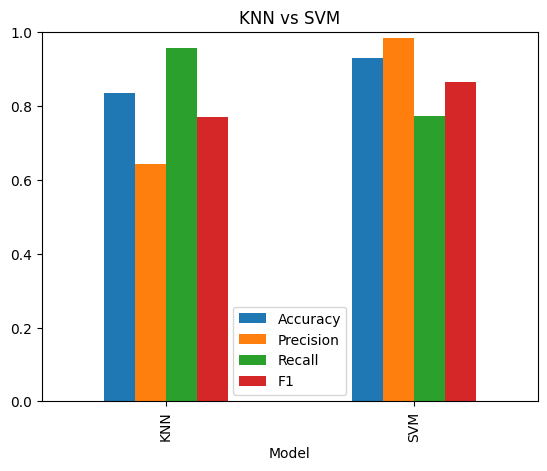

In [5]:
models = {"KNN":KNeighborsClassifier(n_neighbors=5), "SVM":SVC(kernel="rbf")}
rows = []
for name,m in models.items():
    p = m.fit(X_train,y_train).predict(X_test)
    print(name,"confusion matrix:\n",confusion_matrix(y_test,p))
    rows.append([name,accuracy_score(y_test,p),precision_score(y_test,p),recall_score(y_test,p),f1_score(y_test,p)])
res = pd.DataFrame(rows,columns=["Model","Accuracy","Precision","Recall","F1"]); print(res)
res.set_index("Model").plot(kind="bar",ylim=(0,1)); plt.title("KNN vs SVM"); plt.show()